# Оптимизация гиперпараметров

# Переобучение. Слой Dropout

In [1]:
import time
import numpy as np
from torchvision import datasets
from torchvision import transforms
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt

%matplotlib inline



# torch.cuda
Используется для настройки и запуска операций CUDA, отслеживает текущий выбранный графический процессор, и все выделяемые тензоры CUDA по умолчанию будут созданы на этом устройстве.
Для изменения выбранного устройства используется метод torch.cuda.device контекстного менеджера.
Описание в документации https://pytorch.org/docs/stable/notes/cuda.html


In [2]:
# Использование GPU по желанию

if torch.cuda.is_available():
  device = torch.device('cuda')
  print('Работа на GPU')
else:
  device = torch.device('cpu')
  print('Работа на CPU')

# Не забывайте про .to(device)

Работа на GPU


## Загрузка датасета

 В данной работе будет использоваться учебный датасет MNIST
 Создание обучающей и тестовой выборок

In [ ]:
# Подключение cuda
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# гиперпараметры
random_seed = 1
learning_rate = 0.1
num_epochs = 5
batch_size = 64

num_inputs = 784
n_1 = 128
n_2 = 256
num_classes = 10


# Загрузите датасет
# Ваш код
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(root="./data", train=True, transform=transform, download=True)
test_dataset = datasets.MNIST(root="./data", train=False, transform=transform, download=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Сделайте проверку размерности
images, labels = next(iter(train_loader))
print(f"Размерность батча изображений: {images.shape}")  # (batch_size, 1, 28, 28)
print(f"Размерность батча меток: {labels.shape}")  # (batch_size,)

# Перенос данных на устройство (GPU/CPU)
images, labels = images.to(device), labels.to(device)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:00<00:00, 16.1MB/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:00<00:00, 4.46MB/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<00:00, 4.88MB/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw

Размерность батча изображений: torch.Size([64, 1, 28, 28])
Размерность батча меток: torch.Size([64])


# Архитектура MLP
В данном примере посторим архитектуру MLP.
при построении модели будем указывать использу.to(device).
На последнем слоя для подсчета ошибки применим функцию ошибки кросс-энтропия F.softmax(outputs, dim=1)
Входные параметры - количество классов и размерность выходного тензора (количество батчей, выходные значения outputs)
Параметр dim=1 описывает измерение, по которому будет вычисляться Softmax (поэтому каждый срез вдоль dim будет в сумме равен 1)..
Описание в документации https://pytorch.org/docs/stable/generated/torch.nn.Softmax.html

При обучении сети будем выводить ошибки по минибатчам, а точность по эпохам, чтобы посмотреть как проходит процесс обуения.

In [ ]:
class MLP (torch.nn.Module):

    def __init__(self, num_inputs, num_classes):
        super(MLP, self).__init__()

        ### 1st hidden layer
        self.linear_1 = torch.nn.Linear(num_inputs, n_1)
        self.linear_2 = torch.nn.Linear(n_1, n_2)

        self.linear_out = torch.nn.Linear(n_2, num_classes)

    def forward(self, x):
        out = self.linear_1(x)
        out = F.relu(out)
        out = self.linear_2(out)
        out = F.relu(out)

        outputs = self.linear_out(out)
        probas = F.softmax(outputs, dim=1)
        return outputs, probas


torch.manual_seed(random_seed)
model = MLP (num_inputs = num_inputs,
                             num_classes=num_classes)

model = model.to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

## Обучение сети
Выведем статистику Loss по минибатчам? accuracy - по эпохам.

In [ ]:
def compute_accuracy(net, data_loader):
    model.eval()
    correct_pred = 0
    num_examples = 0
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.view(-1, 28*28).to(device)
            labels = labels.to(device)
            outputs, probas = net(images)
            _, predicted = torch.max(probas, 1)
            num_examples += labels.size(0)
            correct_pred += (predicted == labels).sum()

        return correct_pred.float()/num_examples * 100


for epoch in range(num_epochs):
    model.train()
    for i, (images, labels) in enumerate(train_loader):

        images = images.view(-1, 28*28).to(device)
        labels = labels.to(device)

        outputs, probas = model(images)
        Loss = F.cross_entropy( outputs, labels)
        optimizer.zero_grad()
        Loss.backward()
        optimizer.step()

        ###
        if not i % 50:
            print ('Epoch: %03d/%03d | Batch %03d/%03d | Loss: %.4f'
                   %(epoch+1, num_epochs, i,
                     len(train_loader), Loss))

    print('Epoch: %03d/%03d training accuracy: %.2f%%' % (
          epoch+1, num_epochs,
          compute_accuracy(model, train_loader)))
    acc= compute_accuracy(model, train_loader)



Epoch: 001/005 | Batch 000/938 | Loss: 2.3354
Epoch: 001/005 | Batch 050/938 | Loss: 1.2937
Epoch: 001/005 | Batch 100/938 | Loss: 0.6350
Epoch: 001/005 | Batch 150/938 | Loss: 0.4535
Epoch: 001/005 | Batch 200/938 | Loss: 0.5673
Epoch: 001/005 | Batch 250/938 | Loss: 0.2375
Epoch: 001/005 | Batch 300/938 | Loss: 0.3465
Epoch: 001/005 | Batch 350/938 | Loss: 0.4010
Epoch: 001/005 | Batch 400/938 | Loss: 0.2142
Epoch: 001/005 | Batch 450/938 | Loss: 0.2351
Epoch: 001/005 | Batch 500/938 | Loss: 0.2151
Epoch: 001/005 | Batch 550/938 | Loss: 0.1731
Epoch: 001/005 | Batch 600/938 | Loss: 0.2778
Epoch: 001/005 | Batch 650/938 | Loss: 0.3306
Epoch: 001/005 | Batch 700/938 | Loss: 0.3309
Epoch: 001/005 | Batch 750/938 | Loss: 0.2347
Epoch: 001/005 | Batch 800/938 | Loss: 0.2495
Epoch: 001/005 | Batch 850/938 | Loss: 0.0989
Epoch: 001/005 | Batch 900/938 | Loss: 0.3261
Epoch: 001/005 training accuracy: 91.62%
Epoch: 002/005 | Batch 000/938 | Loss: 0.1971
Epoch: 002/005 | Batch 050/938 | Loss: 

# Dropout
 Построим архитектуру MLP c использованием слоя Dropout, чтобы избежать переобучения
Слой Dropout во время обучения случайным образом обнуляет некоторые элементы входного тензора с вероятностью p.



In [ ]:
dropout = 0.5
class MLP (torch.nn.Module):

    def __init__(self, num_inputs, num_classes):
        super(MLP, self).__init__()

        ### 1st hidden layer
        self.linear_1 = torch.nn.Linear(num_inputs, n_1)
        self.linear_2 = torch.nn.Linear(n_1, n_2)
        self.linear_out = torch.nn.Linear(n_2, num_classes)

    def forward(self, x):
        out = self.linear_1(x)
        out = F.relu(out)
        out = F.dropout(out, p=dropout, training=self.training)

        out = self.linear_2(out)
        out = F.relu(out)
        out = F.dropout(out, p=dropout, training=self.training)


        outputs = self.linear_out(out)
        probas = F.softmax(outputs, dim=1)
        return outputs, probas


torch.manual_seed(random_seed)
model = MLP (num_inputs = num_inputs,
                             num_classes=num_classes)

model = model.to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [ ]:
# Обучите сеть и выведите статистику по минибатчам и по эпохам
# Ваш код

# Функция для вычисления точности
def compute_accuracy(model, data_loader):
    model.eval()  # Устанавливаем модель в режим оценки
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.view(-1, num_inputs).to(device)  # Преобразуем изображения в вектор
            labels = labels.to(device)

            outputs, probas = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    return accuracy

# Тренировка модели
for epoch in range(num_epochs):
    model.train()  # Устанавливаем модель в режим тренировки
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_loader):  # train_loader - это ваш DataLoader
        images = images.view(-1, num_inputs).to(device)  # Преобразуем изображения в вектор
        labels = labels.to(device)

        # Прямой проход
        outputs, probas = model(images)
        loss = F.cross_entropy(outputs, labels)  # Функция потерь (кросс-энтропия)

        # Обратный проход
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        # Логирование потерь каждые 50 минибатчей
        if i % 50 == 0:
            print(f"Epoch: {epoch+1:03d}/{num_epochs:03d} | Batch {i:03d}/{len(train_loader):03d} | Loss: {loss.item():.4f}")

    # Выводим статистику по эпохам
    print(f"Epoch: {epoch+1:03d}/{num_epochs:03d} training accuracy: {compute_accuracy(model, train_loader):.2f}%")


Epoch: 001/005 | Batch 000/938 | Loss: 2.3855
Epoch: 001/005 | Batch 050/938 | Loss: 1.6808
Epoch: 001/005 | Batch 100/938 | Loss: 1.1483
Epoch: 001/005 | Batch 150/938 | Loss: 0.8017
Epoch: 001/005 | Batch 200/938 | Loss: 0.7418
Epoch: 001/005 | Batch 250/938 | Loss: 0.6601
Epoch: 001/005 | Batch 300/938 | Loss: 0.8162
Epoch: 001/005 | Batch 350/938 | Loss: 0.7178
Epoch: 001/005 | Batch 400/938 | Loss: 0.4188
Epoch: 001/005 | Batch 450/938 | Loss: 0.4861
Epoch: 001/005 | Batch 500/938 | Loss: 0.4594
Epoch: 001/005 | Batch 550/938 | Loss: 0.4003
Epoch: 001/005 | Batch 600/938 | Loss: 0.5056
Epoch: 001/005 | Batch 650/938 | Loss: 0.5870
Epoch: 001/005 | Batch 700/938 | Loss: 0.3695
Epoch: 001/005 | Batch 750/938 | Loss: 0.3372
Epoch: 001/005 | Batch 800/938 | Loss: 0.4258
Epoch: 001/005 | Batch 850/938 | Loss: 0.2947
Epoch: 001/005 | Batch 900/938 | Loss: 0.5984
Epoch: 001/005 training accuracy: 89.56%
Epoch: 002/005 | Batch 000/938 | Loss: 0.6239
Epoch: 002/005 | Batch 050/938 | Loss: 

# Нормализация

## Обучение глубоких нейронных сетей
Обучение глубоких нейронных сетей осложняется тем, что распределение входов каждого слоя меняется в процессе обучения, поскольку меняются параметры предыдущих слоев. Это замедляет обучение, требуя тщательной инифиализации параметров.
Это явление называется внутренним ковариационным сдвигом и решается  путем нормализации входов слоев.
Основа метода заключается в том, что нормализация является частью архитектуры модели и выполняется для каждого минибатча
Пакетная нормализация позволяет  использовать гораздо более высокие скорости обучения. Она также действует как регуляризатор, в некоторых случаях устраняя необходимость в Dropout.



## Создание архитектуры сети
В данной работе будут использоваться слои нормализации для предотвращения внутреннего ковариационного сдвига в

Слой нормализации - класс  torch.nn.BatchNorm1d(C) C — размерность каналов входных данных
torch.nn.BatchNorm1d(num_features, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True, device=None, dtype=None)

Среднее значение и стандартное отклонение рассчитываются для каждого измерения мини-батчей: γ и β — это обучаемые векторы параметров размера C. По умолчанию элементы  γ установлены в 1, а элементы β установлены на 0.
Также по умолчанию во время обучения этот слой продолжает выполнять оценки вычисленного среднего значения и дисперсии, которые затем используются для нормализации во время оценки. Текущие оценки сохраняются со значением momentum по умолчанию 0,1.
Описание в документации https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html

Ниже представлена архитектура MLP с подключением слоя нормализации перед активационной функцией.


In [ ]:
class MLP_1(torch.nn.Module):

    def __init__(self, num_inputs, num_classes):
        super(MLP_1, self).__init__()

        ### 1 скрытый слой
        self.linear_1 = torch.nn.Linear(num_inputs, n_1)
        # Подключение слоя нормализации перед активационной функцией
        # которая стандартно используется
        self.linear_1_bn = torch.nn.BatchNorm1d(n_1)

        ### 2 скрытый слойr
        self.linear_2 = torch.nn.Linear(n_1, n_2)
        self.linear_2_bn = torch.nn.BatchNorm1d(n_2)

        ### выходной слой
        self.linear_out = torch.nn.Linear(n_2, num_classes)


    def forward(self, x):
        out = self.linear_1(x)
        # Как правило, перед активационной функцией используется нормализация
        out = self.linear_1_bn(out)
        out = F.relu(out)

        out = self.linear_2(out)
        out = self.linear_2_bn(out)
        out = F.relu(out)

        outputs = self.linear_out(out)
        probas = F.softmax( outputs, dim=1)
        return  outputs, probas


torch.manual_seed(random_seed)
model = MLP_1(num_inputs=num_inputs,
                             num_classes=num_classes)

model = model.to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [ ]:
# Обучите сеть и выведите статистику по минибатчам и по эпохам
# Ваш код

# Обучение сети
num_epochs = 3  # количество эпох
batch_size = 64  # размер минибатча
dropout = 0.5  # вероятность дропаута
random_seed = 42  # случайное начальное значение
learning_rate = 0.01  # скорость обучения

# Переводим модель в режим обучения
model.train()

# Функция для вычисления точности на обучающих данных
def calculate_accuracy(output, target):
    _, predicted = torch.max(output, 1)  # получаем метки с максимальной вероятностью
    correct = (predicted == target).sum().item()  # подсчитываем количество правильных предсказаний
    return correct / target.size(0) * 100  # вычисляем точность в процентах

# Начинаем обучение
for epoch in range(num_epochs):
    running_loss = 0.0
    running_accuracy = 0.0
    for batch_idx, (data, target) in enumerate(train_loader):  # train_loader — это ваш загрузчик данных
        data, target = data.to(device), target.to(device)  # Переносим данные на нужное устройство (GPU или CPU)

        # Преобразуем входные данные в одномерный вектор, если это необходимо
        data = data.view(data.size(0), -1)  # Преобразуем изображение в вектор (например, 28x28 -> 784)

        optimizer.zero_grad()  # Обнуляем градиенты
        outputs, probas = model(data)  # Прогоняем данные через модель

        loss = F.cross_entropy(outputs, target)  # Вычисляем кросс-энтропию для классификации
        loss.backward()  # Вычисляем градиенты

        optimizer.step()  # Обновляем параметры модели

        # Статистика
        running_loss += loss.item()
        running_accuracy += calculate_accuracy(outputs, target)

        if batch_idx % 50 == 0:  # Выводим статистику каждые 50 минибатчей
            print(f'Epoch: {epoch + 1:03}/{num_epochs:03} | Batch {batch_idx:03}/{len(train_loader):03} | Loss: {loss.item():.4f}')

    # Выводим статистику по эпохам
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = running_accuracy / len(train_loader)
    print(f'Epoch: {epoch + 1:03}/{num_epochs:03} training accuracy: {epoch_accuracy:.2f}% | Training loss: {epoch_loss:.4f}')

Epoch: 001/003 | Batch 000/938 | Loss: 2.4170
Epoch: 001/003 | Batch 050/938 | Loss: 0.4206
Epoch: 001/003 | Batch 100/938 | Loss: 0.2043
Epoch: 001/003 | Batch 150/938 | Loss: 0.1749
Epoch: 001/003 | Batch 200/938 | Loss: 0.2211
Epoch: 001/003 | Batch 250/938 | Loss: 0.1170
Epoch: 001/003 | Batch 300/938 | Loss: 0.1797
Epoch: 001/003 | Batch 350/938 | Loss: 0.1879
Epoch: 001/003 | Batch 400/938 | Loss: 0.1951
Epoch: 001/003 | Batch 450/938 | Loss: 0.2625
Epoch: 001/003 | Batch 500/938 | Loss: 0.0911
Epoch: 001/003 | Batch 550/938 | Loss: 0.1004
Epoch: 001/003 | Batch 600/938 | Loss: 0.1772
Epoch: 001/003 | Batch 650/938 | Loss: 0.1449
Epoch: 001/003 | Batch 700/938 | Loss: 0.2058
Epoch: 001/003 | Batch 750/938 | Loss: 0.0677
Epoch: 001/003 | Batch 800/938 | Loss: 0.0314
Epoch: 001/003 | Batch 850/938 | Loss: 0.0743
Epoch: 001/003 | Batch 900/938 | Loss: 0.0522
Epoch: 001/003 training accuracy: 94.02% | Training loss: 0.2046
Epoch: 002/003 | Batch 000/938 | Loss: 0.0698
Epoch: 002/003 

In [ ]:
#####  Проверьте работу на тестовой выборке.

# Переводим модель в режим оценки
model.eval()

# Переменные для подсчета потерь и точности на тестовых данных
test_loss = 0.0
test_accuracy = 0.0
correct = 0
total = 0

# Отключаем вычисление градиентов, так как нам они не нужны при тестировании
with torch.no_grad():
    for data, target in test_loader:  # test_loader — это ваш загрузчик тестовых данных
        data, target = data.to(device), target.to(device)  # Переносим данные на нужное устройство (GPU или CPU)

        # Преобразуем входные данные в одномерный вектор, если это необходимо
        data = data.view(data.size(0), -1)  # Преобразуем изображение в вектор (например, 28x28 -> 784)

        outputs, probas = model(data)  # Прогоняем данные через модель

        # Вычисляем потери
        loss = F.cross_entropy(outputs, target)
        test_loss += loss.item()

        # Вычисляем точность
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == target).sum().item()
        total += target.size(0)

# Средняя потеря на тестовой выборке
test_loss /= len(test_loader)

# Точность на тестовой выборке
accuracy = 100 * correct / total

print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {accuracy:.2f}%')

Test Loss: 0.0687
Test Accuracy: 97.89%


## Создание архитектуры сети с подключением слоя нормализации после активационной функции

Создайте архитектуру MLP с подключением слоя нормализации после активационной функцией.
Обучите сеть
выведите результаты.

In [ ]:
######## Ваш код
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms

# Определяем архитектуру MLP с BatchNorm после активации
class MLP_with_BatchNorm(nn.Module):
    def __init__(self, num_inputs, num_classes):
        super(MLP_with_BatchNorm, self).__init__()

        # 1 скрытый слой
        self.linear_1 = nn.Linear(num_inputs, 128)
        self.bn_1 = nn.BatchNorm1d(128)

        # 2 скрытый слой
        self.linear_2 = nn.Linear(128, 64)
        self.bn_2 = nn.BatchNorm1d(64)

        # 3 скрытый слой
        self.linear_3 = nn.Linear(64, 32)
        self.bn_3 = nn.BatchNorm1d(32)

        # Выходной слой
        self.linear_out = nn.Linear(32, num_classes)

    def forward(self, x):
        out = self.linear_1(x)
        out = F.relu(out)
        out = self.bn_1(out)  # Слой нормализации после активации

        out = self.linear_2(out)
        out = F.relu(out)
        out = self.bn_2(out)  # Слой нормализации после активации

        out = self.linear_3(out)
        out = F.relu(out)
        out = self.bn_3(out)  # Слой нормализации после активации

        outputs = self.linear_out(out)
        probas = F.softmax(outputs, dim=1)
        return outputs, probas

# Инициализация устройства, модели, оптимизатора
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MLP_with_BatchNorm(num_inputs=784, num_classes=10).to(device)  # 784 — размерность входа (для MNIST)

# Создаем оптимизатор
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

# Для MNIST данных
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(trainset, batch_size=64, shuffle=True)
test_loader = DataLoader(testset, batch_size=64, shuffle=False)

# Обучение модели
def train_model(model, train_loader, optimizer, num_epochs=5):
    model.train()

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct = 0
        total = 0
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)

            # Преобразуем данные в одномерный вектор
            data = data.view(data.size(0), -1)  # Преобразуем изображения в векторы (например, 28x28 -> 784)

            optimizer.zero_grad()  # Обнуляем градиенты
            outputs, probas = model(data)  # Прогоняем данные через модель

            loss = F.cross_entropy(outputs, target)  # Вычисляем кросс-энтропию
            loss.backward()  # Вычисляем градиенты
            optimizer.step()  # Обновляем параметры модели

            running_loss += loss.item()

            # Подсчитываем точность
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == target).sum().item()
            total += target.size(0)

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%')

# Запуск обучения
train_model(model, train_loader, optimizer, num_epochs=5)

Epoch [1/5], Loss: 0.2808, Accuracy: 91.78%
Epoch [2/5], Loss: 0.1409, Accuracy: 95.67%
Epoch [3/5], Loss: 0.1123, Accuracy: 96.54%
Epoch [4/5], Loss: 0.0938, Accuracy: 97.10%
Epoch [5/5], Loss: 0.0803, Accuracy: 97.46%


In [ ]:
##### Выведите результаты.  Проверьте работу на тестовой выборке. Сделайте вывод

# Проверка модели на тестовых данных
def test_model(model, test_loader):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)

            data = data.view(data.size(0), -1)

            outputs, probas = model(data)
            loss = F.cross_entropy(outputs, target)
            test_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == target).sum().item()
            total += target.size(0)

    test_loss /= len(test_loader)
    accuracy = 100 * correct / total

    print(f'Test Loss: {test_loss:.4f}')
    print(f'Test Accuracy: {accuracy:.2f}%')

# Запуск тестирования
test_model(model, test_loader)

Test Loss: 0.0844
Test Accuracy: 97.51%


Потери постепенно уменьшаются, что свидетельствует о хорошем процессе обучения.

Точность (Accuracy) на обучающих данных возрастает, начиная с 91.78% в первой эпохе и достигая 97.46% в последней эпохе, что говорит об эффективном обучении модели.

Потери на тестовой выборке составляют 0.0844, что также подтверждает хорошую способность модели к обобщению.

Точность на тестовой выборке составляет 97.51%, что также является хорошим результатом.
Вывод:

Модель успешно обучена и показывает высокую точность как на обучающих, так и на тестовых данных. Это указывает на то, что архитектура сети и слой нормализации, расположенный после активации, эффективно способствуют улучшению обучения и стабильности .

#  Аугментация

Один из методов борьбы с переобучением является увеличение выборки с использованием аугментации
, можно воспользоваться базовым классом `ImageFolder`.
при помощи параметра `transform` можно скомпоновать преобразования для изображений. (лабораторная работа №2)

Для компоновки функции из модуля v2 используйте `Compose`.Параметры:
* ToImage() - преобразование в `Image` (подкласс torch.Tensor)
* RandomVerticalFlip() - случайное отзеркаливание
* ToDtype(torch.float32, scale=True) - преобразование из int во float
* Normalize() - нормализация изображений по полученным средним и стандартным отклонениям.

По желанию:
* RandomRotation() - поворот на случайный угол в указанном диапазоне
* Можете попробовать и другие варианты преобразований. [Документация API V2](https://pytorch.org/vision/stable/transforms.html#v2-api-reference-recommended)

 При обучении используете весь набор обязательных преобразований, при проверке требуется только преобразовать изображение к тензору с плавающей точкой и провести нормализацию.

# Задание 1.
 Загрузить датасет bus для решения задачи классификации входящих и выхдящих пассажиров. Провести аугментацию датчсета с
  использованием , создать 3 архитектуры сети, провести обучение с использованием обучающей и валидационной выборок, проверить на тестовой выборке, вывесит лучшую архитектуру.

## Порядок выполнения

1. Загрузить датасет bus для решения задачи классификации;
2. Подготовить transforms, DataSet и DataLoader;
3. Создать 3 архитектуры сети c использованием слоя Batchnorm2d, за основу можно взять архитектуру LeNet. Документация Batchnorm2d https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html
4. Обучите сеть и выведите графики результатов на тренировочной и валидационной выборках.
5. Оценить результаты лучшей модели на тестовой выборке.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from tqdm import tqdm
import zipfile

# Указываем путь к архиву
zip_file_path = '/content/drive/MyDrive/bus.zip'
extracted_folder_path = '/content/drive/MyDrive/bus/'

# Распаковываем архив с прогресс-баром
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    for file in tqdm(zip_ref.namelist(), desc="Распаковка"):
        zip_ref.extract(file, extracted_folder_path)

print("Распаковка завершена!")

Распаковка: 100%|██████████| 9083/9083 [1:01:43<00:00,  2.45it/s]

Распаковка завершена!


In [8]:
!pip install split-folders

import splitfolders

# Путь к исходной папке с данными
input_folder = '/content/drive/MyDrive/bus/'

# Путь для сохранения разделенных данных
output_folder = '/content/drive/MyDrive/bus_split/'

# Разделение данных в соотношении 80% train, 10% val, 10% test
splitfolders.ratio(input_folder, output=output_folder, seed=42, ratio=(0.8, 0.1, 0.1))

Copying files: 9081 files [03:19, 45.54 files/s]


In [9]:
data_dir = '/content/drive/MyDrive/bus_split/'

# Проверка структуры датасета
print("Содержимое папки bus_split:", os.listdir(data_dir))
print("Содержимое папки train:", os.listdir(os.path.join(data_dir, 'train')))
print("Содержимое папки val:", os.listdir(os.path.join(data_dir, 'val')))
print("Содержимое папки test:", os.listdir(os.path.join(data_dir, 'test')))

Содержимое папки bus_split: ['train', 'val', 'test']
Содержимое папки train: ['Входящий', 'Выходящий']
Содержимое папки val: ['Входящий', 'Выходящий']
Содержимое папки test: ['Входящий', 'Выходящий']


In [10]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Определяем трансформации для аугментации данных
transform = transforms.Compose([
    transforms.Resize((32, 32)),  # Изменение размера изображений
    transforms.RandomHorizontalFlip(),  # Аугментация: случайное отражение по горизонтали
    transforms.ToTensor(),  # Преобразование в тензор
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # Нормализация
])

# Загружаем датасеты
train_dataset = datasets.ImageFolder(root=os.path.join(output_folder, 'train'), transform=transform)
val_dataset = datasets.ImageFolder(root=os.path.join(output_folder, 'val'), transform=transform)
test_dataset = datasets.ImageFolder(root=os.path.join(output_folder, 'test'), transform=transform)

# Создаем DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [11]:
# Создание 3 архитектур на основе LeNet с BatchNorm2d
import torch.nn as nn
import torch.nn.functional as F

# Архитектура 1: Базовая LeNet с BatchNorm2d
class LeNetVariant1(nn.Module):
    def __init__(self, num_classes=2):
        super(LeNetVariant1, self).__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)  # 3 входных канала, 6 выходных, ядро 5x5
        self.bn1 = nn.BatchNorm2d(6)
        self.pool = nn.MaxPool2d(2, 2)  # Слой пулинга
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.bn2 = nn.BatchNorm2d(16)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)  # Полносвязный слой
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)  # Выходной слой

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = x.view(-1, 16 * 5 * 5)  # Выравнивание тензора
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Архитектура 2: Увеличенное количество фильтров
class LeNetVariant2(nn.Module):
    def __init__(self, num_classes=2):
        super(LeNetVariant2, self).__init__()
        self.conv1 = nn.Conv2d(3, 12, 5)
        self.bn1 = nn.BatchNorm2d(12)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(12, 32, 5)
        self.bn2 = nn.BatchNorm2d(32)
        self.fc1 = nn.Linear(32 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = x.view(-1, 32 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Архитектура 3: Уменьшенное количество фильтров
class LeNetVariant3(nn.Module):
    def __init__(self, num_classes=2):
        super(LeNetVariant3, self).__init__()
        self.conv1 = nn.Conv2d(3, 8, 5)
        self.bn1 = nn.BatchNorm2d(8)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(8, 24, 5)
        self.bn2 = nn.BatchNorm2d(24)
        self.fc1 = nn.Linear(24 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = x.view(-1, 24 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

Training Model 1
Epoch 1/10, Train Loss: 0.5759, Train Acc: 71.48%, Val Loss: 0.5549, Val Acc: 72.33%
Epoch 2/10, Train Loss: 0.5090, Train Acc: 74.92%, Val Loss: 0.5251, Val Acc: 74.75%
Epoch 3/10, Train Loss: 0.4637, Train Acc: 78.73%, Val Loss: 0.4562, Val Acc: 79.82%
Epoch 4/10, Train Loss: 0.4162, Train Acc: 81.68%, Val Loss: 0.4153, Val Acc: 83.13%
Epoch 5/10, Train Loss: 0.3728, Train Acc: 83.74%, Val Loss: 0.4154, Val Acc: 80.82%
Epoch 6/10, Train Loss: 0.3470, Train Acc: 85.09%, Val Loss: 0.3629, Val Acc: 85.56%
Epoch 7/10, Train Loss: 0.3161, Train Acc: 86.33%, Val Loss: 0.3523, Val Acc: 84.67%
Epoch 8/10, Train Loss: 0.2892, Train Acc: 87.83%, Val Loss: 0.3095, Val Acc: 87.10%
Epoch 9/10, Train Loss: 0.2666, Train Acc: 88.57%, Val Loss: 0.3442, Val Acc: 83.68%
Epoch 10/10, Train Loss: 0.2481, Train Acc: 89.54%, Val Loss: 0.2841, Val Acc: 88.53%


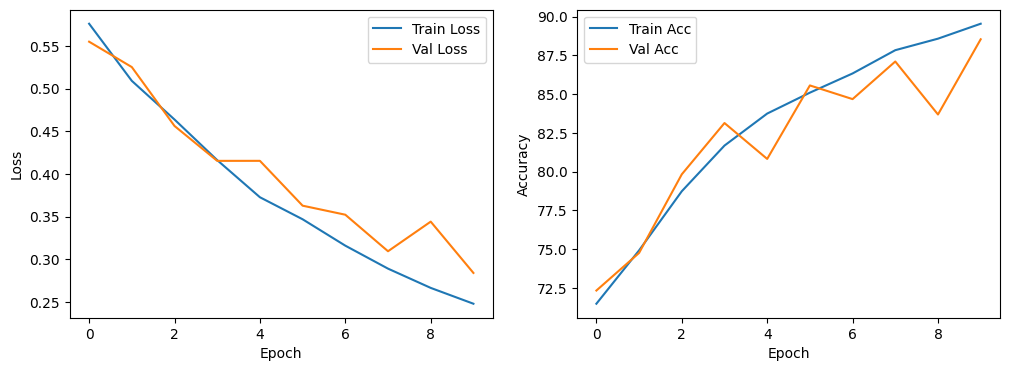

Training Model 2
Epoch 1/10, Train Loss: 0.5510, Train Acc: 70.95%, Val Loss: 0.5123, Val Acc: 73.98%
Epoch 2/10, Train Loss: 0.4547, Train Acc: 79.20%, Val Loss: 0.4701, Val Acc: 78.28%
Epoch 3/10, Train Loss: 0.3984, Train Acc: 82.13%, Val Loss: 0.4185, Val Acc: 80.71%
Epoch 4/10, Train Loss: 0.3431, Train Acc: 85.17%, Val Loss: 0.3447, Val Acc: 85.34%
Epoch 5/10, Train Loss: 0.2929, Train Acc: 87.61%, Val Loss: 0.2940, Val Acc: 87.32%
Epoch 6/10, Train Loss: 0.2551, Train Acc: 89.40%, Val Loss: 0.2747, Val Acc: 88.64%
Epoch 7/10, Train Loss: 0.2332, Train Acc: 90.03%, Val Loss: 0.2702, Val Acc: 88.97%
Epoch 8/10, Train Loss: 0.2154, Train Acc: 91.23%, Val Loss: 0.2168, Val Acc: 90.08%
Epoch 9/10, Train Loss: 0.1947, Train Acc: 91.91%, Val Loss: 0.2113, Val Acc: 91.40%
Epoch 10/10, Train Loss: 0.1737, Train Acc: 92.66%, Val Loss: 0.1874, Val Acc: 91.95%


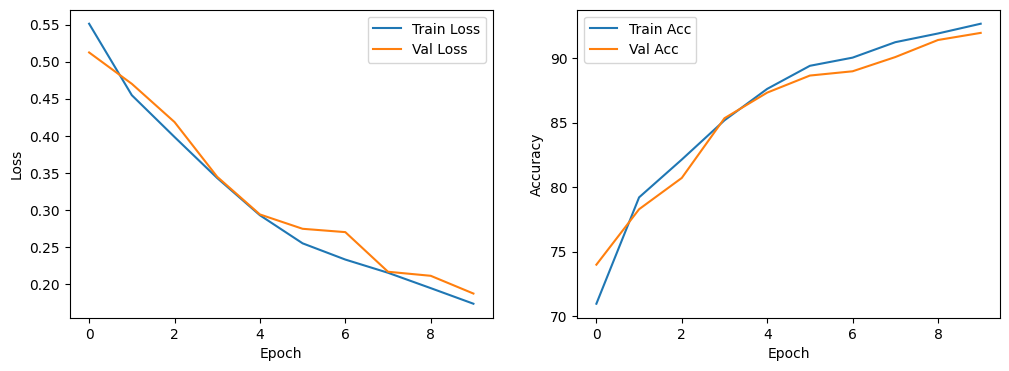

Training Model 3
Epoch 1/10, Train Loss: 0.5705, Train Acc: 70.57%, Val Loss: 0.5442, Val Acc: 72.11%
Epoch 2/10, Train Loss: 0.4998, Train Acc: 74.97%, Val Loss: 0.4898, Val Acc: 77.18%
Epoch 3/10, Train Loss: 0.4419, Train Acc: 80.77%, Val Loss: 0.4486, Val Acc: 80.26%
Epoch 4/10, Train Loss: 0.3863, Train Acc: 83.55%, Val Loss: 0.3831, Val Acc: 84.67%
Epoch 5/10, Train Loss: 0.3423, Train Acc: 85.53%, Val Loss: 0.4319, Val Acc: 78.83%
Epoch 6/10, Train Loss: 0.3073, Train Acc: 86.96%, Val Loss: 0.3219, Val Acc: 86.44%
Epoch 7/10, Train Loss: 0.2908, Train Acc: 87.49%, Val Loss: 0.3146, Val Acc: 87.54%
Epoch 8/10, Train Loss: 0.2575, Train Acc: 89.32%, Val Loss: 0.2526, Val Acc: 89.20%
Epoch 9/10, Train Loss: 0.2340, Train Acc: 90.17%, Val Loss: 0.2768, Val Acc: 88.86%
Epoch 10/10, Train Loss: 0.2232, Train Acc: 90.57%, Val Loss: 0.2298, Val Acc: 91.18%


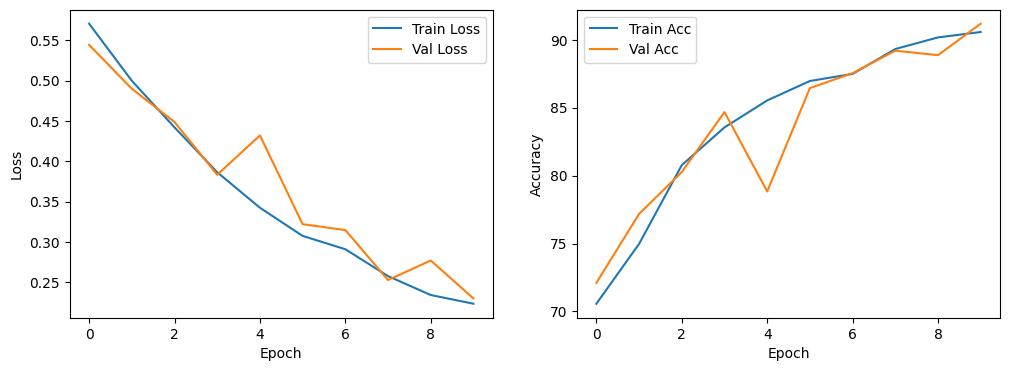

In [12]:
import torch.optim as optim
import matplotlib.pyplot as plt

# Функция для обучения модели
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    train_losses, val_losses = [], []
    train_acc, val_acc = [], []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_accuracy = 100 * correct_train / total_train
        train_losses.append(train_loss)
        train_acc.append(train_accuracy)

        # Валидация
        model.eval()
        val_running_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_running_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = val_running_loss / len(val_loader)
        val_accuracy = 100 * correct_val / total_val
        val_losses.append(val_loss)
        val_acc.append(val_accuracy)

        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")

    # Графики потерь и точности
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Val Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(train_acc, label='Train Acc')
    plt.plot(val_acc, label='Val Acc')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

# Обучение моделей
models = [LeNetVariant1(), LeNetVariant2(), LeNetVariant3()]
for i, model in enumerate(models):
    print(f"Training Model {i+1}")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
    train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10)

In [17]:
# Выбираем вторую модель (LeNetVariant2)
best_model = models[1]  # Индексация начинается с 0

# Переводим модель в режим оценки
best_model.eval()

# Переменные для подсчета правильных предсказаний и общего количества примеров
correct_test = 0
total_test = 0

# Отключаем вычисление градиентов для ускорения и экономии памяти
with torch.no_grad():
    for inputs, labels in test_loader:
        # Получаем предсказания модели
        outputs = best_model(inputs)

        # Определяем predicted (предсказанные классы)
        _, predicted = torch.max(outputs.data, 1)

        # Обновляем счетчики
        total_test += labels.size(0)
        correct_test += (predicted == labels).sum().item()

# Вычисляем точность на тестовой выборке
accuracy = 100 * correct_test / total_test
print(f"Accuracy of the second model (LeNetVariant2) on test set: {accuracy:.2f}%")

Accuracy of the second model (LeNetVariant2) on test set: 92.20%


#  Задание 2.

Порядок выполнения
1.  Загрузите датасет fmr.zip.
2.	Создайте 3 архитектуры сверточной нейронной сети для распознавания данных из набора fmr.zip. Обучите сеть и выведите результаты на тренировочной и валидационной выборках.
4.	Проверьте работу сети на тестовой выборке. Добейтесь точности не менее 85%.
5.	Загрузите файлы с картинками из интернета или создайте свои фотографии.
6.	Проверьте работу сети на собственных картинках.

In [25]:
import zipfile
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

# Распаковка архива
zip_file_path = '/content/drive/MyDrive/fmr.zip'
extracted_folder_path = '/content/drive/MyDrive/fmr/'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extracted_folder_path)

print("Распаковка завершена!")

Распаковка завершена!


In [62]:
import os
import shutil
import random

# Путь к исходной папке
input_folder = '/content/drive/MyDrive/fmr'
output_folder = '/content/drive/MyDrive/fmr_organized'

# Создаем папки для train, val и test
for split in ['train', 'val', 'test']:
    for class_name in ['Ferrari', 'Mercedes', 'Renault']:
        os.makedirs(os.path.join(output_folder, split, class_name), exist_ok=True)

# Функция для распределения файлов
def organize_data(input_folder, output_folder, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1):
    for class_name in ['Ferrari', 'Mercedes', 'Renault']:
        # Получаем список всех файлов для текущего класса
        class_files = [f for f in os.listdir(os.path.join(input_folder, class_name)) if f.endswith('.png')]
        random.shuffle(class_files)  # Перемешиваем файлы

        # Вычисляем количество файлов для каждой выборки
        train_count = int(len(class_files) * train_ratio)
        val_count = int(len(class_files) * val_ratio)
        test_count = len(class_files) - train_count - val_count

        # Копируем файлы в соответствующие папки
        for i, filename in enumerate(class_files):
            src = os.path.join(input_folder, class_name, filename)
            if i < train_count:
                dst = os.path.join(output_folder, 'train', class_name, filename)
            elif i < train_count + val_count:
                dst = os.path.join(output_folder, 'val', class_name, filename)
            else:
                dst = os.path.join(output_folder, 'test', class_name, filename)
            shutil.copy(src, dst)

# Организуем данные
organize_data(input_folder, output_folder)
print("Данные успешно организованы!")

Данные успешно организованы!


In [63]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Преобразования для изображений
transform = transforms.Compose([
    transforms.Resize((64, 64)),  # Изменение размера изображений
    transforms.ToTensor(),         # Преобразование в тензор
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Нормализация
])

# Загрузка данных
train_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/fmr_organized/train', transform=transform)
val_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/fmr_organized/val', transform=transform)
test_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/fmr_organized/test', transform=transform)

# Создание DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Проверка классов
print("Классы в тренировочной выборке:", train_dataset.class_to_idx)
print("Классы в валидационной выборке:", val_dataset.class_to_idx)
print("Классы в тестовой выборке:", test_dataset.class_to_idx)

Классы в тренировочной выборке: {'Ferrari': 0, 'Mercedes': 1, 'Renault': 2}
Классы в валидационной выборке: {'Ferrari': 0, 'Mercedes': 1, 'Renault': 2}
Классы в тестовой выборке: {'Ferrari': 0, 'Mercedes': 1, 'Renault': 2}


In [64]:
import torch
import torch.nn as nn
import torch.optim as optim

# Архитектура модели
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 3)  # 3 класса: Ferrari, Mercedes, Renault

    def forward(self, x):
        x = self.pool(nn.functional.relu(self.conv1(x)))
        x = self.pool(nn.functional.relu(self.conv2(x)))
        x = x.view(-1, 64 * 16 * 16)
        x = nn.functional.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Инициализация модели
model = CNN()

# Определение функции потерь и оптимизатора
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Перемещение модели на GPU (если доступно)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=3, bias=True)
)

In [65]:
# Функция для обучения
def train(model, train_loader, val_loader, criterion, optimizer, num_epochs=10):
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Обнуление градиентов
            optimizer.zero_grad()

            # Прямой проход
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Обратный проход и оптимизация
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # Валидация
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Train Loss: {running_loss/len(train_loader):.4f}, "
              f"Val Loss: {val_loss/len(val_loader):.4f}, "
              f"Val Accuracy: {100 * correct / total:.2f}%")

# Обучение модели
train(model, train_loader, val_loader, criterion, optimizer, num_epochs=10)

Epoch 1/10, Train Loss: 0.9402, Val Loss: 0.8570, Val Accuracy: 58.94%
Epoch 2/10, Train Loss: 0.8096, Val Loss: 0.8434, Val Accuracy: 62.17%
Epoch 3/10, Train Loss: 0.7014, Val Loss: 0.8325, Val Accuracy: 60.12%
Epoch 4/10, Train Loss: 0.5728, Val Loss: 0.8441, Val Accuracy: 62.46%
Epoch 5/10, Train Loss: 0.4266, Val Loss: 0.9214, Val Accuracy: 63.93%
Epoch 6/10, Train Loss: 0.2680, Val Loss: 1.1794, Val Accuracy: 63.34%
Epoch 7/10, Train Loss: 0.1281, Val Loss: 1.3890, Val Accuracy: 61.00%
Epoch 8/10, Train Loss: 0.0848, Val Loss: 1.6025, Val Accuracy: 61.00%
Epoch 9/10, Train Loss: 0.0732, Val Loss: 1.6145, Val Accuracy: 60.41%
Epoch 10/10, Train Loss: 0.0276, Val Loss: 1.9248, Val Accuracy: 61.58%


In [66]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Точность на тестовых данных: {100 * correct / total:.2f}%")

Точность на тестовых данных: 62.72%


In [71]:
from PIL import Image
import torchvision.transforms as transforms

# Функция для предсказания класса изображения
def predict_image(model, img_path):
    img = Image.open(img_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    img_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output, 1)
        class_labels = list(train_dataset.class_to_idx.keys())
        return class_labels[predicted.item()]

# Пример использования
img_path = '/content/Renault.jpg'
predicted_class = predict_image(model, img_path)
print(f"Предсказанный класс: {predicted_class}")

Предсказанный класс: Ferrari


In [68]:
from PIL import Image
import torchvision.transforms as transforms

# Функция для предсказания класса изображения
def predict_image(model, img_path):
    img = Image.open(img_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    img_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output, 1)
        class_labels = list(train_dataset.class_to_idx.keys())
        return class_labels[predicted.item()]

# Пример использования
img_path = '/content/Мерседес.jpg'
predicted_class = predict_image(model, img_path)
print(f"Предсказанный класс: {predicted_class}")

Предсказанный класс: Mercedes


In [69]:
# Функция для предсказания класса изображения
def predict_image(model, img_path):
    img = Image.open(img_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    img_tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output, 1)
        class_labels = list(train_dataset.class_to_idx.keys())
        return class_labels[predicted.item()]

# Пример использования
img_path = '/content/Феррари.jpg'
predicted_class = predict_image(model, img_path)
print(f"Предсказанный класс: {predicted_class}")

Предсказанный класс: Ferrari


In [72]:
from torchvision import transforms

# Преобразования для тренировочных данных (с аугментацией)
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),  # Случайное отражение по горизонтали
    transforms.RandomRotation(10),      # Случайный поворот на ±10 градусов
    transforms.Resize((64, 64)),        # Изменение размера изображений
    transforms.ToTensor(),              # Преобразование в тензор
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Нормализация
])

# Преобразования для валидационных и тестовых данных (без аугментации)
val_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Загрузка данных с аугментацией
train_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/fmr_organized/train', transform=train_transform)
val_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/fmr_organized/val', transform=val_transform)
test_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/fmr_organized/test', transform=val_transform)

# Создание DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [73]:
import torch.nn as nn

class ImprovedCNN(nn.Module):
    def __init__(self):
        super(ImprovedCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout = nn.Dropout(0.5)  # Добавляем Dropout
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 3)  # 3 класса: Ferrari, Mercedes, Renault

    def forward(self, x):
        x = self.pool(nn.functional.relu(self.conv1(x)))
        x = self.pool(nn.functional.relu(self.conv2(x)))
        x = self.pool(nn.functional.relu(self.conv3(x)))
        x = x.view(-1, 128 * 8 * 8)
        x = self.dropout(x)  # Применяем Dropout
        x = nn.functional.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Инициализация модели
model = ImprovedCNN().to(device)

In [74]:
from torch.optim.lr_scheduler import StepLR

# Оптимизатор с L2-регуляризацией (weight decay)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

# Планировщик скорости обучения
scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  # Уменьшаем learning rate каждые 5 эпох

Epoch 1/20, Train Loss: 0.9577, Val Loss: 0.9044, Val Accuracy: 56.60%
Epoch 2/20, Train Loss: 0.8918, Val Loss: 0.8864, Val Accuracy: 55.43%
Epoch 3/20, Train Loss: 0.8541, Val Loss: 0.8684, Val Accuracy: 55.43%
Epoch 4/20, Train Loss: 0.8068, Val Loss: 0.9004, Val Accuracy: 57.48%
Epoch 5/20, Train Loss: 0.7820, Val Loss: 0.8023, Val Accuracy: 62.46%
Epoch 6/20, Train Loss: 0.7250, Val Loss: 0.7946, Val Accuracy: 65.10%
Epoch 7/20, Train Loss: 0.7086, Val Loss: 0.7975, Val Accuracy: 63.93%
Epoch 8/20, Train Loss: 0.6997, Val Loss: 0.7921, Val Accuracy: 64.52%
Epoch 9/20, Train Loss: 0.6927, Val Loss: 0.7944, Val Accuracy: 63.34%
Epoch 10/20, Train Loss: 0.6852, Val Loss: 0.7828, Val Accuracy: 65.10%
Epoch 11/20, Train Loss: 0.6768, Val Loss: 0.7835, Val Accuracy: 65.10%
Epoch 12/20, Train Loss: 0.6666, Val Loss: 0.7842, Val Accuracy: 64.52%
Epoch 13/20, Train Loss: 0.6638, Val Loss: 0.7848, Val Accuracy: 64.81%
Epoch 14/20, Train Loss: 0.6718, Val Loss: 0.7853, Val Accuracy: 64.81%
E

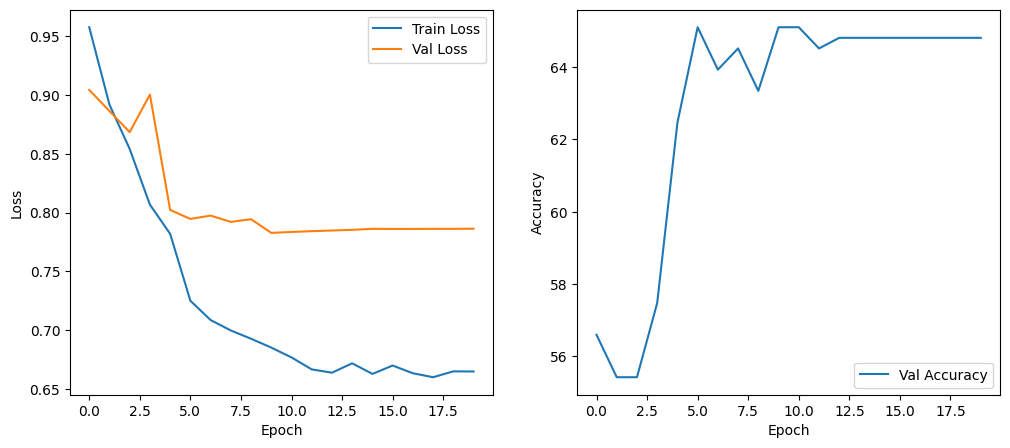

In [75]:
import matplotlib.pyplot as plt

# Функция для обучения
def train(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=10):
    train_losses = []
    val_losses = []
    val_accuracies = []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # Валидация
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        # Сохраняем метрики
        train_losses.append(running_loss / len(train_loader))
        val_losses.append(val_loss / len(val_loader))
        val_accuracies.append(100 * correct / total)

        # Обновляем learning rate
        scheduler.step()

        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Train Loss: {train_losses[-1]:.4f}, "
              f"Val Loss: {val_losses[-1]:.4f}, "
              f"Val Accuracy: {val_accuracies[-1]:.2f}%")

    # Визуализация
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Val Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, label='Val Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()

# Обучение модели
train(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20)

In [76]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Точность на тестовых данных: {100 * correct / total:.2f}%")

Точность на тестовых данных: 69.36%


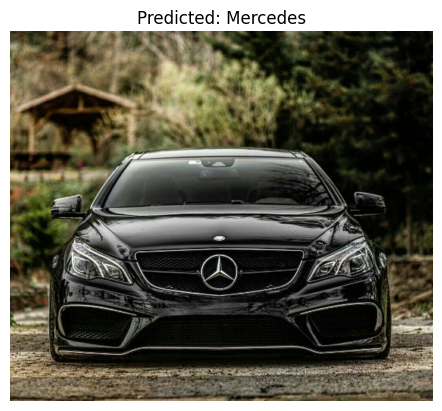

Предсказанный класс: Mercedes


In [79]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

# Функция для предсказания класса изображения с визуализацией
def predict_and_visualize(model, img_path):
    # Загрузка изображения
    img = Image.open(img_path).convert('RGB')

    # Преобразования для изображения
    transform = transforms.Compose([
        transforms.Resize((64, 64)),  # Изменение размера изображения
        transforms.ToTensor(),        # Преобразование в тензор
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Нормализация
    ])

    # Применение преобразований
    img_tensor = transform(img).unsqueeze(0).to(device)

    # Предсказание
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output, 1)
        class_labels = list(train_dataset.class_to_idx.keys())
        predicted_class = class_labels[predicted.item()]

    # Визуализация изображения с предсказанным классом
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_class}")
    plt.axis('off')  # Отключаем оси
    plt.show()

    return predicted_class

# Пример использования
img_path = '/content/Мерседес.jpg'  # Замените на путь к вашему изображению
predicted_class = predict_and_visualize(model, img_path)
print(f"Предсказанный класс: {predicted_class}")

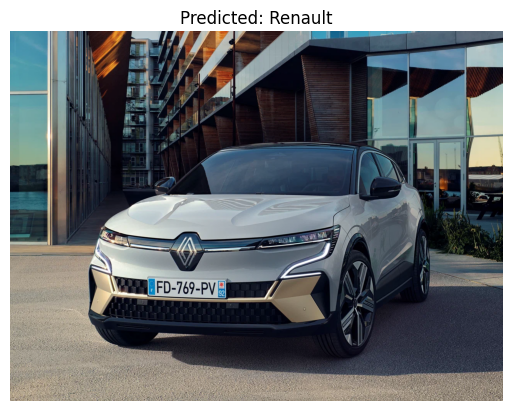

Предсказанный класс: Renault


In [84]:
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

# Функция для предсказания класса изображения с визуализацией
def predict_and_visualize(model, img_path):
    # Загрузка изображения
    img = Image.open(img_path).convert('RGB')

    # Преобразования для изображения
    transform = transforms.Compose([
        transforms.Resize((64, 64)),  # Изменение размера изображения
        transforms.ToTensor(),        # Преобразование в тензор
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Нормализация
    ])

    # Применение преобразований
    img_tensor = transform(img).unsqueeze(0).to(device)

    # Предсказание
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output, 1)
        class_labels = list(train_dataset.class_to_idx.keys())
        predicted_class = class_labels[predicted.item()]

    # Визуализация изображения с предсказанным классом
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_class}")
    plt.axis('off')  # Отключаем оси
    plt.show()

    return predicted_class

# Пример использования
img_path = '/content/Renault 2.webp'
predicted_class = predict_and_visualize(model, img_path)
print(f"Предсказанный класс: {predicted_class}")

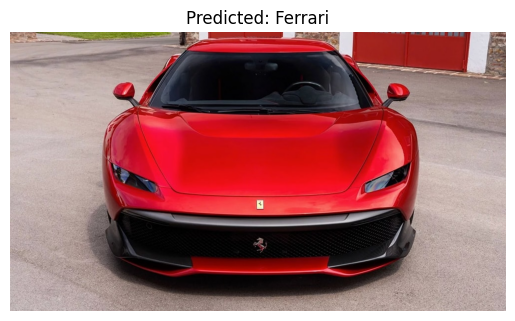

Предсказанный класс: Ferrari


In [85]:
# Функция для предсказания класса изображения с визуализацией
def predict_and_visualize(model, img_path):
    # Загрузка изображения
    img = Image.open(img_path).convert('RGB')

    # Преобразования для изображения
    transform = transforms.Compose([
        transforms.Resize((64, 64)),  # Изменение размера изображения
        transforms.ToTensor(),        # Преобразование в тензор
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Нормализация
    ])

    # Применение преобразований
    img_tensor = transform(img).unsqueeze(0).to(device)

    # Предсказание
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        _, predicted = torch.max(output, 1)
        class_labels = list(train_dataset.class_to_idx.keys())
        predicted_class = class_labels[predicted.item()]

    # Визуализация изображения с предсказанным классом
    plt.imshow(img)
    plt.title(f"Predicted: {predicted_class}")
    plt.axis('off')  # Отключаем оси
    plt.show()

    return predicted_class

# Пример использования
img_path = '/content/Феррари 2.jpg'
predicted_class = predict_and_visualize(model, img_path)
print(f"Предсказанный класс: {predicted_class}")